# WICOS: pre-processing
Every spectrogram is pre-processed in four steps (`preprocess_clip` in `src/preprocessing.py`):

1. **Noise removal:** one noise level per clip, the median of the **far Doppler bins** that the hand never reaches.
   Every pixel not more than a **margin** above that level is set to the threshold (noise level + margin).
2. **Doppler crop:** keep only the bins near 0 Hz that hold gesture energy.
3. **Scaling:** threshold → 0, maximum → 1.
4. **Resize:** linear interpolation to 128 × 128 (Doppler × time).

This notebook first shows the four steps on one clip, then **derives** the constants they use:

* **Far bins** (`FAR_OFFSET = 340`): the Doppler bins used to estimate each clip's noise level, i.e. all bins at least
  340 bins from 0 Hz (bins 0–59 and 740–799).
* **Margin** (`MARGIN_DB = 10`): how far above the noise level a pixel must be to count as gesture.
* **Doppler crop** (`CROP_OFFSET = 310`): keep bins 90–709, outside which less than 1% of the training pixels per bin
  lie above the threshold.

Everything is derived on the **training clips only**, so no test information enters the pre-processing.
Every step only uses the clip itself and these fixed constants, so it can then be applied to every clip without leakage.
Doppler bins are written as the distance from zero Doppler, `|k| = |bin − 400|`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter, zoom

sys.path.insert(0, str(Path("../src").resolve()))
import preprocessing
from build_dataset import load_data, split

FIG_DIR = Path("../reports/figures")

spectrograms, metadata = load_data()
idx_train, idx_test, _ = split(metadata)
specs = [spectrograms[i] for i in idx_train]
meta = metadata.iloc[idx_train].reset_index(drop=True)
gestures, persons = meta.gesture.to_numpy(), meta.person.to_numpy()
GEST = sorted(np.unique(gestures))
print(f"{len(specs)} training clips of {len(spectrograms)}")

N_DOPPLER, ZD = 800, 400
dist = np.abs(np.arange(N_DOPPLER) - ZD)                      # |k| of every Doppler bin
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00"]
C_GEST = dict(zip(GEST, OKABE))

def style(ax):
    ax.grid(alpha=0.25, lw=0.5)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

768 training clips of 960


## The four steps on one clip
The cell runs the steps one by one on a training clip and checks that `preprocess_clip` gives the same result.
Crop and scaling are shown together in one panel.

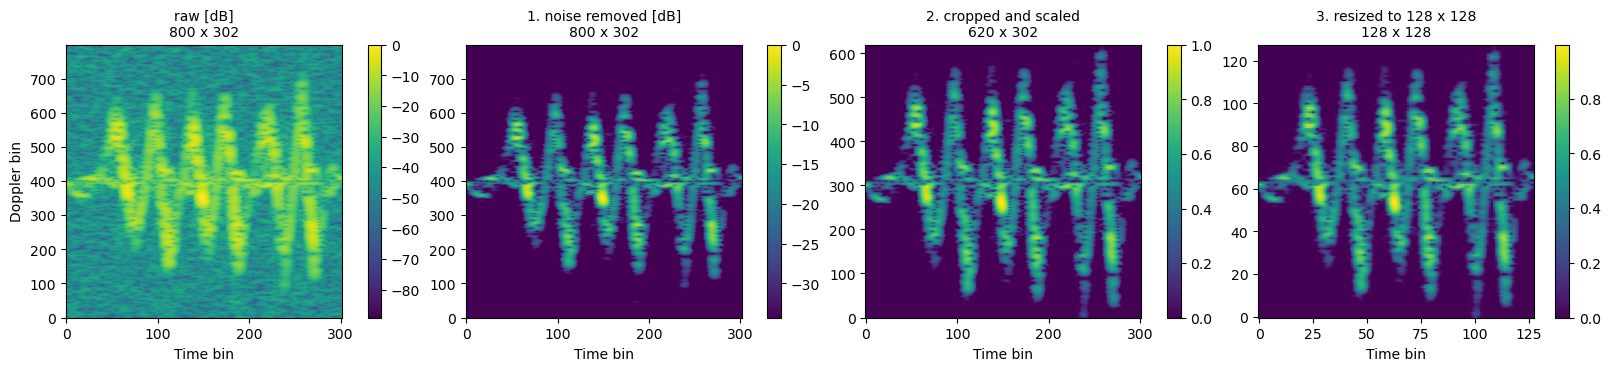

Same as preprocess_clip: True


In [2]:
x = specs[2]
x_clean, thr = preprocessing.remove_noise(x)                                     # 1. noise removal
x_crop = x_clean[preprocessing.DOPPLER_CROP[0]:preprocessing.DOPPLER_CROP[1]]    # 2. Doppler crop
x_scaled = (x_crop - thr) / (x_crop.max() - thr)                                 # 3. scaling: threshold -> 0, maximum -> 1
x_img = zoom(x_scaled, (128 / x_scaled.shape[0], 128 / x_scaled.shape[1]), order=1)  # 4. resize

steps = {"raw [dB]": x, "1. noise removed [dB]": x_clean,
         "2. cropped and scaled": x_scaled, "3. resized to 128 x 128": x_img}
fig, axes = plt.subplots(1, len(steps), figsize=(16, 3.6), constrained_layout=True)
for ax, (name, img) in zip(axes, steps.items()):
    im = ax.imshow(img, aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(f"{name}\n{img.shape[0]} x {img.shape[1]}", fontsize=10)
    ax.set_xlabel("Time bin")
    fig.colorbar(im, ax=ax)
axes[0].set_ylabel("Doppler bin")
fig.savefig(FIG_DIR / "prepro_all_steps.pdf", bbox_inches="tight")
plt.show()

print("Same as preprocess_clip:", np.allclose(np.clip(x_img, 0, 1), preprocessing.preprocess_clip(x)))

## 1. Which bins contain only noise? → far bins

The median magnitude per Doppler bin (`doppler_profile_persons.pdf` in `1_data_exploration.ipynb`) peaks around 0 Hz, where the
gesture is, and levels off to a flat line towards both band edges, for every gesture and person. There the spectrogram contains
only noise. By inspection we take the outer 60 bins on each side as the **far bins**: |k| ≥ 340, i.e. bins 0–59 and 740–799
(120 bins). The noise level of a clip is the median of all its far-bin pixels.

The cell below checks how much the noise level would change if the boundary were moved: for every boundary, the difference
with the level of the 60 far bins, over all training clips. If it hardly changes, the exact choice of 60 bins does not matter.

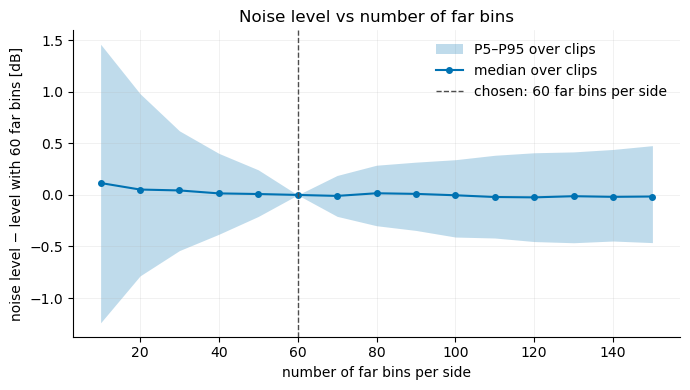

 far bins per side  median    P5  P95
                10    0.12 -1.24 1.46
                20    0.05 -0.79 0.98
                30    0.04 -0.54 0.62
                40    0.01 -0.38 0.40
                50    0.01 -0.21 0.24
                60    0.00  0.00 0.00
                70   -0.01 -0.21 0.19
                80    0.02 -0.30 0.29
                90    0.01 -0.34 0.32
               100   -0.00 -0.41 0.34
               110   -0.02 -0.42 0.38
               120   -0.02 -0.45 0.41
               130   -0.01 -0.46 0.42
               140   -0.02 -0.45 0.44
               150   -0.02 -0.46 0.48


In [3]:
far = np.isin(np.arange(N_DOPPLER), preprocessing.FAR_BINS)           # the 60 far bins per side
lvl_ref = np.array([preprocessing.noise_level(s) for s in specs])     # noise level with the 60 far bins
n_side = np.arange(10, 151, 10)                                       # number of far bins per side
rows = []
for n in n_side:
    l = np.array([np.median(s[np.r_[0:n, N_DOPPLER - n:N_DOPPLER]]) for s in specs])
    d = l - lvl_ref
    rows.append((n, np.median(d), np.percentile(d, 5), np.percentile(d, 95)))
sens = pd.DataFrame(rows, columns=["far bins per side", "median", "P5", "P95"])

n_ref = ZD - preprocessing.FAR_OFFSET
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(n_side, sens.P5, sens.P95, color="#0072B2", alpha=0.25, lw=0, label="P5–P95 over clips")
ax.plot(n_side, sens["median"], color="#0072B2", lw=1.5, marker="o", ms=4, label="median over clips")
ax.axvline(n_ref, color="0.3", ls="--", lw=1, label=f"chosen: {n_ref} far bins per side")
ax.set(xlabel="number of far bins per side", ylabel=f"noise level − level with {n_ref} far bins [dB]",
       title="Noise level vs number of far bins")
ax.legend(frameon=False)
style(ax)
plt.tight_layout(); plt.savefig(FIG_DIR / "noise_far_bins.pdf", bbox_inches="tight"); plt.show()

print(sens.round(2).to_string(index=False))

**Result.** Taking anywhere between 40 and 150 far bins per side changes the noise level by less than ±0.5 dB in 90% of the
clips, with a median change of ≈ 0 dB. So the exact choice of 60 bins is not critical. With fewer bins (below ~30 per side)
the estimate only gets noisier because fewer pixels are left for the median.

## 2. How far above the noise level? → margin

Thresholding at the noise level (the median) would still pass half of the noise pixels, so a margin is added. For complex
Gaussian noise the power per pixel $P$ is exponentially distributed with mean $\mu$ (Rayleigh amplitude). The probability that
a noise pixel exceeds a threshold $p$ (false alarm) is

$$P_\text{fa} = \Pr(P > p) = e^{-p/\mu} \;\Rightarrow\; p = \mu \ln(1/P_\text{fa}), \qquad p_{50} = \mu \ln 2 .$$

The margin above the median does not depend on the unknown noise power $\mu$, only on the chosen $P_\text{fa}$:

$$\Delta_\text{dB} = 10 \log_{10}\frac{p}{p_{50}} = 10 \log_{10}\frac{\ln(1/P_\text{fa})}{\ln 2}.$$

With $P_\text{fa} = 10^{-3}$ (threshold at the 99.9th percentile of the noise) this gives $\Delta_\text{dB} \approx 10$ dB.

The cell computes the margin from this formula and compares the theory with the data: all far-bin pixels of all training
clips, relative to each clip's noise level.

margin for P_fa = 0.001: 9.985 dB  (pipeline uses MARGIN_DB = 10.0 dB)


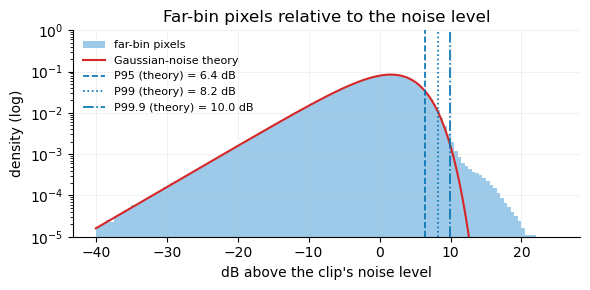

far-bin pixels above the median: P95 6.5, P99 8.7, P99.9 13.4 dB (theory 6.4, 8.2, 10.0 dB)
far-bin pixels above the 10 dB margin: 0.39% (theory 0.1%)


In [4]:
P_FA = 1e-3                                                     # false-alarm probability: share of noise pixels kept
margin_theory = 10 * np.log10(np.log(1 / P_FA) / np.log(2))
print(f"margin for P_fa = {P_FA:g}: {margin_theory:.3f} dB  (pipeline uses MARGIN_DB = {preprocessing.MARGIN_DB} dB)")

rel = np.concatenate([(s[far] - l).ravel() for s, l in zip(specs, lvl_ref)])   # far-bin pixels relative to the level
q = np.array([95, 99, 99.9])
pcts_theory = 10 * np.log10(np.log(1 / (1 - q / 100)) / np.log(2))   # noise percentiles above the median
pcts = np.percentile(rel, q)

fig, ax = plt.subplots(figsize=(6, 3))
x = np.linspace(-40, 25, 500); p = 10 ** (x / 10); lam = np.log(2)
ax.hist(rel, bins=np.linspace(-40, 25, 131), density=True, color="#9ECAE9", log=True, label="far-bin pixels")
ax.plot(x, lam * np.exp(-lam * p) * p * np.log(10) / 10, color="#D62728", lw=1.5, label="Gaussian-noise theory")
for v, lab, ls in zip(pcts_theory, ["P95", "P99", "P99.9"], ["--", ":", "-."]):
    ax.axvline(v, color="#0072B2", ls=ls, lw=1.2, label=f"{lab} (theory) = {v:.1f} dB")
ax.set(ylim=(1e-5, 1), xlabel="dB above the clip's noise level", ylabel="density (log)",
       title="Far-bin pixels relative to the noise level")
ax.legend(frameon=False, fontsize=8)
style(ax)
plt.tight_layout(); plt.savefig(FIG_DIR / "noise_margin.pdf", bbox_inches="tight"); plt.show()

print(f"far-bin pixels above the median: P95 {pcts[0]:.1f}, P99 {pcts[1]:.1f}, P99.9 {pcts[2]:.1f} dB "
      f"(theory {pcts_theory[0]:.1f}, {pcts_theory[1]:.1f}, {pcts_theory[2]:.1f} dB)")
print(f"far-bin pixels above the {preprocessing.MARGIN_DB:.0f} dB margin: {100 * (rel > preprocessing.MARGIN_DB).mean():.2f}% "
      f"(theory {100 * P_FA:.1f}%)")

**Result.** The formula gives 9.99 dB, rounded to **10 dB** (`MARGIN_DB`).

The bulk of the far-bin pixels follows the theory (P95 6.5 and P99 8.7 dB against 6.4 and 8.2 dB), so the complex Gaussian
assumption holds for the noise. Above ~10 dB the measured tail is heavier than the theory: P99.9 is 13.4 dB instead of 10.0 dB,
and 0.39% of the far-bin pixels stay above the 10 dB margin instead of 0.1%. These extra pixels are not noise but the broadband
stripes of the click gesture, whose abrupt stop spreads energy over all Doppler bins for a few frames. They are gesture energy,
so they should stay above the threshold; the margin is therefore set from the noise theory, not from the measured tail.

So the noise removal per clip is

$$\text{threshold} = \operatorname{median}(x_\text{far bins}) + 10\ \text{dB},$$

and every pixel at or below the threshold is set to the threshold. The noise level follows each recording, the margin is the
same for all clips.

In [5]:
# Noise removal on every training clip
cleaned = [preprocessing.remove_noise(s) for s in specs]        # (x_clean, threshold) per clip
thresholds = np.array([t for _, t in cleaned])
removed = np.array([(s <= t).mean() for s, t in zip(specs, thresholds)])
print(f"threshold {thresholds.min():.1f} to {thresholds.max():.1f} dB; pixels set to the threshold per clip "
      f"{removed.min():.1%} to {removed.max():.1%} (mean {removed.mean():.1%})")

threshold -49.4 to -6.9 dB; pixels set to the threshold per clip 59.0% to 99.4% (mean 89.7%)


## 3. Doppler crop

The far bins contain (almost) only noise, so they can be removed to get a finer Doppler resolution after resizing. Per Doppler
bin we take all training clips together and count the share of pixels above the clip's threshold (noise level + margin).
A bin is removed if that share is at most `TIME_FRAC`. The crop is symmetric: half-width $w$ is the smallest value such that
every bin with |k| ≥ $w$ can be removed, so the crop keeps bins `[400 − w, 400 + w)`.

Pure noise exceeds the threshold in a share $P_\text{fa}$ (0.1%) of the pixels, so `TIME_FRAC` must be above that. Change
`TIME_FRAC` below to see its effect; the pipeline uses the result as `CROP_OFFSET` in `src/preprocessing.py`.

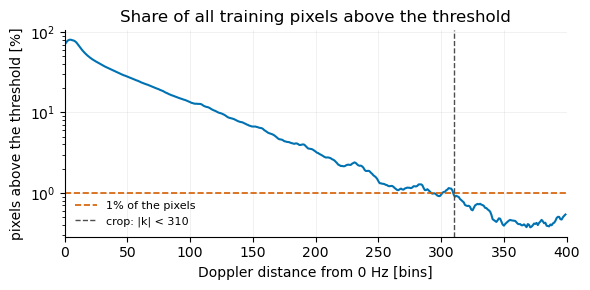

crop |k| < 310, bins 90-709 (620 bins, Doppler factor 4.8 after resizing)
share in the far bins: 0.39% (pure noise: 0.1%)
pipeline: DOPPLER_CROP = bins 90-709


In [6]:
TIME_FRAC = 0.01            # a bin is removed if at most this share of its pixels (all training clips) is above the threshold

def half_width(removable):
    # smallest w such that every bin with |k| >= w is removable (w = 401: nothing can be removed)
    keep = dist[~removable]
    return keep.max() + 1 if keep.size else 0

above = [s > t for s, t in zip(specs, thresholds)]                                  # pixels above the threshold
pooled = sum(a.sum(1) for a in above) / sum(a.shape[1] for a in above)               # share of all pixels, per bin
w_pool = half_width(pooled <= TIME_FRAC)

fig, ax = plt.subplots(figsize=(6,3))
k_pos = np.arange(ZD)
pooled_k = pd.Series(pooled).groupby(dist).max().reindex(k_pos)                      # worst of the two sides
ax.plot(k_pos, 100 * pooled_k, color="#0072B2", lw=1.5)
ax.axhline(100 * TIME_FRAC, color="#D55E00", ls="--", lw=1.2, label=f"{TIME_FRAC:.0%} of the pixels")
if w_pool <= ZD:
    ax.axvline(w_pool, color="0.3", ls="--", lw=1, label=f"crop: |k| < {w_pool}")
ax.set(yscale="log", xlim=(0, ZD), xlabel="Doppler distance from 0 Hz [bins]", ylabel="pixels above the threshold [%]",
       title="Share of all training pixels above the threshold")
ax.legend(frameon=False, fontsize=8)
style(ax)
plt.tight_layout(); plt.savefig(FIG_DIR / "crop_rule.pdf", bbox_inches="tight"); plt.show()

if w_pool > ZD:
    print("no bin can be removed")
else:
    print(f"crop |k| < {w_pool}, bins {ZD - w_pool}-{ZD + w_pool - 1} ({2 * w_pool} bins, "
          f"Doppler factor {2 * w_pool / 128:.1f} after resizing)")
print(f"share in the far bins: {100 * pooled[far].mean():.2f}% (pure noise: {100 * P_FA:.1f}%)")
print(f"pipeline: DOPPLER_CROP = bins {preprocessing.DOPPLER_CROP[0]}-{preprocessing.DOPPLER_CROP[1] - 1}")

# example clips for the last section: the clip with the median SNR of each gesture
snr = -lvl_ref                                                      # 0 dB peak - noise level
examples = []
for G in GEST:
    ii = np.flatnonzero(gestures == G)
    examples.append(ii[np.argsort(snr[ii])[len(ii) // 2]])

**Result (TIME_FRAC = 1%).** The share of pixels above the threshold falls steadily away from 0 Hz and reaches 1% at
**|k| ≈ 310**, so the crop keeps bins 90–709. In the far bins the share is about 0.4%, four times pure noise ($P_\text{fa}$ =
0.1%): these are the broadband click stripes, which lift every Doppler bin for a few frames. A limit close to the noise level
can therefore not be reached by any crop. The pipeline uses this crop: `CROP_OFFSET = 310`.

## 4. Scaling and resizing
* **Scaling:** $(x - \text{thr}) / (\max x - \text{thr})$, so the threshold becomes 0 and the clip maximum 1. Every clip is peak-normalised
  to 0 dB, so the denominator is the clip's own dynamic range above the threshold (0 dB − threshold). This removes the
  gain differences between recordings (person B is ~15 dB noisier, see `1_data_exploration.ipynb`). The values stay on a dB
  scale, so weak parts of the gesture remain visible next to the strongest pixel.
* **Resize to 128 × 128:** linear interpolation.
  * *Doppler:* the 620 cropped bins are scaled by the **same** factor (620/128 ≈ 4.8) for every clip, so a row keeps the same
    velocity meaning in every image. The cost is resolution: a pinch, which stays within |k| < 165, covers only about
    2 · 165 / 4.8 ≈ 68 of the 128 rows.
  * *Time:* the clips have 43 to 448 time bins, so every clip is stretched to 128 columns. This removes the duration
    from the images; the envelope features keep it as the gesture length T (`3_features.ipynb`).
  * 128 is close to the median clip length, keeps the flattened image small enough for PCA (16 384 values), and divides
    by 2 repeatedly for the pooling layers of the CNN. It was not tuned.

The cell below pre-processes every clip (training and test) with these fixed constants.

In [7]:
X_img = preprocessing.preprocess(spectrograms)
print(f"X_img: {X_img.shape}, values from {X_img.min():.2f} to {X_img.max():.2f}")

X_img: (960, 128, 128), values from 0.00 to 1.00


## Summary for the report

| parameter | value | how it was chosen |
|---|---|---|
| far bins | \|k\| ≥ 340 (bins 0–59, 740–799) | by inspection: the median magnitude per Doppler bin is flat there; the level changes < ±0.5 dB for any 40–150 far bins per side |
| noise level | median of the far-bin pixels, per clip | robust to the few far-bin pixels with gesture energy (click stripes) |
| margin | 10 dB | $10\log_{10}(\ln(1/P_\text{fa}) / \ln 2)$ with $P_\text{fa} = 10^{-3}$ (99.9th percentile of complex Gaussian noise); the far-bin data follow the theory up to ~10 dB, the heavier tail above is the click stripes |
| Doppler crop | bins 90–709 (\|k\| < 310) | per bin, less than 1% of all training pixels above the threshold outside the crop (section 3) |
| scaling | threshold → 0, max → 1 | removes gain differences between recordings; per clip, no learned constant |
| resize | 128 × 128 | fixed Doppler factor (rows keep their velocity meaning); time stretched per clip (duration kept in the features) |

## Example: raw vs pre-processed
One training clip per gesture (the clip with the median SNR of that gesture). Top: raw spectrogram in dB (colour range from
5 dB below the noise level to the 0 dB peak), with the bins removed by the crop shaded and the crop boundaries dashed. Bottom: the output of
`preprocessing.preprocess_clip` (noise removed, cropped to bins 90–709, scaled to [0, 1], resized to 128 × 128).

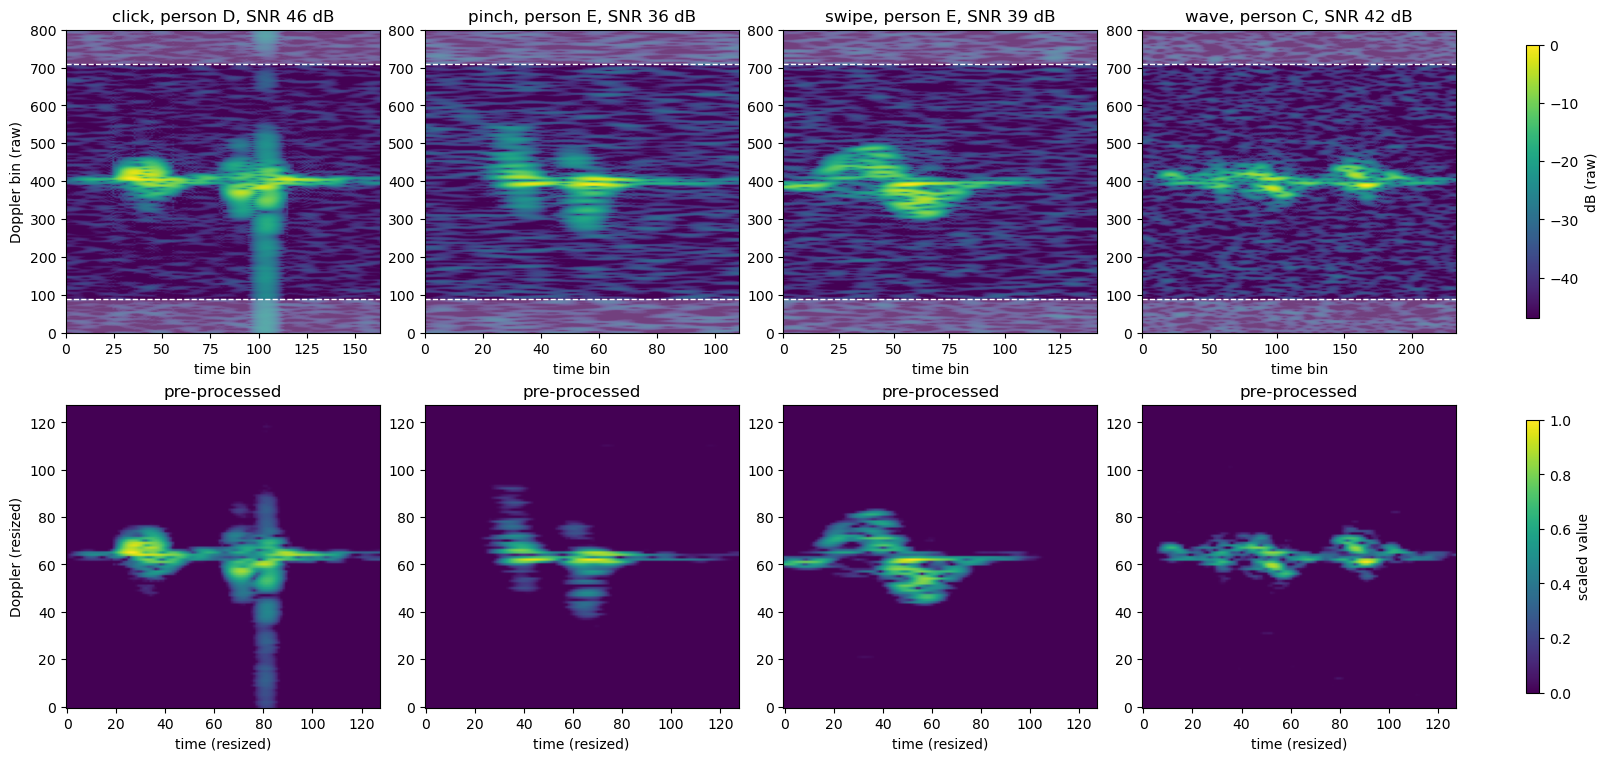

In [8]:
# examples: the median-SNR clip per gesture, chosen in section 3
fig, ax = plt.subplots(2, len(examples), figsize=(4 * len(examples), 7.5), layout="constrained")
for c, i in enumerate(examples):
    s = specs[i]
    a = ax[0, c]
    im0 = a.imshow(s, aspect="auto", origin="lower", cmap="viridis", vmin=preprocessing.noise_level(s) - 5, vmax=0,
                   extent=[0, s.shape[1], 0, N_DOPPLER])
    for lo, hi in [(0, preprocessing.DOPPLER_CROP[0]), (preprocessing.DOPPLER_CROP[1], N_DOPPLER)]:   # removed by the crop
        a.axhspan(lo, hi, color="white", alpha=0.25, lw=0)
    for b in preprocessing.DOPPLER_CROP:
        a.axhline(b, color="white", ls="--", lw=1)
    a.set(title=f"{gestures[i]}, person {persons[i]}, SNR {snr[i]:.0f} dB", xlabel="time bin")
    a = ax[1, c]
    im1 = a.imshow(preprocessing.preprocess_clip(s), aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
    a.set(title="pre-processed", xlabel="time (resized)")
ax[0, 0].set_ylabel("Doppler bin (raw)")
ax[1, 0].set_ylabel("Doppler (resized)")
fig.colorbar(im0, ax=ax[0], label="dB (raw)", shrink=0.9)
fig.colorbar(im1, ax=ax[1], label="scaled value", shrink=0.9)
plt.savefig(FIG_DIR / "prepro_examples.pdf", bbox_inches="tight"); plt.show()